# Tugas - Klasifikasi Angka Tulisan Tangan (MNIST) dengan JST

Tugas ini membangun JST menggunakan Keras untuk mengklasifikasikan angka tulisan tangan dari dataset **MNIST** ke dalam 10 kelas (0-9).

Eksperimen yang dilakukan:

1. Baseline: 2 hidden layer dengan 128 dan 64 neuron, aktivasi ReLU.
2. Mengubah jumlah neuron menjadi 256 dan 128.
3. Menambahkan satu hidden layer lagi (128-64-32).
4. Membandingkan aktivasi Sigmoid dan ReLU pada konfigurasi baseline.

Setiap konfigurasi dibandingkan berdasarkan akurasi data uji dan waktu pelatihan.

## 1. Import Library dan Konfigurasi

In [2]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical

SEED = 42
EPOCHS = 5
BATCH_SIZE = 128

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print('TensorFlow:', tf.__version__)

TensorFlow: 2.21.0


## 2. Load Dataset MNIST

Data gambar 28x28 dinormalisasi dari rentang 0-255 menjadi 0-1, lalu label diubah menjadi one-hot encoding.

In [3]:
# 1. Load dataset MNIST
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalisasi data (0-255 menjadi 0-1)
X_train = X_train / 255.0
X_test = X_test / 255.0

# One-hot encoding label
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train_cat.shape)
print('y_test :', y_test_cat.shape)

X_train: (60000, 28, 28)
X_test : (10000, 28, 28)
y_train: (60000, 10)
y_test : (10000, 10)


## 3. Fungsi Membangun Model

Fungsi menerima daftar jumlah neuron hidden layer sehingga jumlah layer dapat divariasikan.

In [4]:
def build_model(hidden_layers=(128, 64), activation='relu'):
    layers = [
        # Ubah gambar 28x28 menjadi vektor
        tf.keras.Input(shape=(28, 28)),
        Flatten(),
    ]

    for units in hidden_layers:
        layers.append(Dense(units, activation=activation))

    # Output layer (10 kelas)
    layers.append(Dense(10, activation='softmax'))

    model = Sequential(layers)

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy'],
    )

    return model

## 4. Fungsi Training dan Evaluasi

Seed diatur ulang sebelum setiap model dibuat agar perbandingan antar konfigurasi adil.

In [5]:
def run_experiment(name, hidden_layers, activation):
    tf.keras.utils.set_random_seed(SEED)

    model = build_model(hidden_layers, activation)

    start = time.perf_counter()
    history = model.fit(
        X_train, y_train_cat,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_split=0.1,
        verbose=0,
    )
    training_time = time.perf_counter() - start

    test_loss, test_accuracy = model.evaluate(X_test, y_test_cat, verbose=0)

    return {
        'name': name,
        'hidden_layers': hidden_layers,
        'activation': activation,
        'history': history.history,
        'test_loss': test_loss,
        'test_accuracy': test_accuracy,
        'training_time': training_time,
        'parameters': model.count_params(),
        'model': model,
    }

## 5. Menjalankan Eksperimen

In [6]:
configs = [
    ('Baseline 128-64 ReLU', (128, 64), 'relu'),
    ('Neuron 256-128 ReLU', (256, 128), 'relu'),
    ('Tambah Layer 128-64-32 ReLU', (128, 64, 32), 'relu'),
    ('Baseline 128-64 Sigmoid', (128, 64), 'sigmoid'),
]

results = []

for name, hidden_layers, activation in configs:
    result = run_experiment(name, hidden_layers, activation)
    results.append(result)

    print(f"{name}: test accuracy={result['test_accuracy']:.4f}, "
          f"test loss={result['test_loss']:.4f}, "
          f"waktu={result['training_time']:.2f} s, "
          f"parameter={result['parameters']:,}")

Baseline 128-64 ReLU: test accuracy=0.9690, test loss=0.1013, waktu=15.06 s, parameter=109,386
Neuron 256-128 ReLU: test accuracy=0.9728, test loss=0.0907, waktu=22.22 s, parameter=235,146
Tambah Layer 128-64-32 ReLU: test accuracy=0.9707, test loss=0.0965, waktu=17.95 s, parameter=111,146
Baseline 128-64 Sigmoid: test accuracy=0.9556, test loss=0.1454, waktu=15.22 s, parameter=109,386


## 6. Tabel Perbandingan

In [7]:
tabel = pd.DataFrame([
    {
        'Konfigurasi': r['name'],
        'Hidden Layers': '-'.join(str(u) for u in r['hidden_layers']),
        'Aktivasi': r['activation'].capitalize(),
        'Test Accuracy': round(r['test_accuracy'], 4),
        'Test Loss': round(r['test_loss'], 4),
        'Waktu (s)': round(r['training_time'], 2),
        'Parameter': r['parameters'],
    }
    for r in results
])

tabel

,Konfigurasi,Hidden Layers,Aktivasi,Test Accuracy,Test Loss,Waktu (s),Parameter
0,Baseline 128-64 ReLU,128-64,Relu,0.9690,0.1013,15.06,109386
1,Neuron 256-128 ReLU,256-128,Relu,0.9728,0.0907,22.22,235146
2,Tambah Layer 128-64-32 ReLU,128-64-32,Relu,0.9707,0.0965,17.95,111146
3,Baseline 128-64 Sigmoid,128-64,Sigmoid,0.9556,0.1454,15.22,109386


## 7. Grafik Training

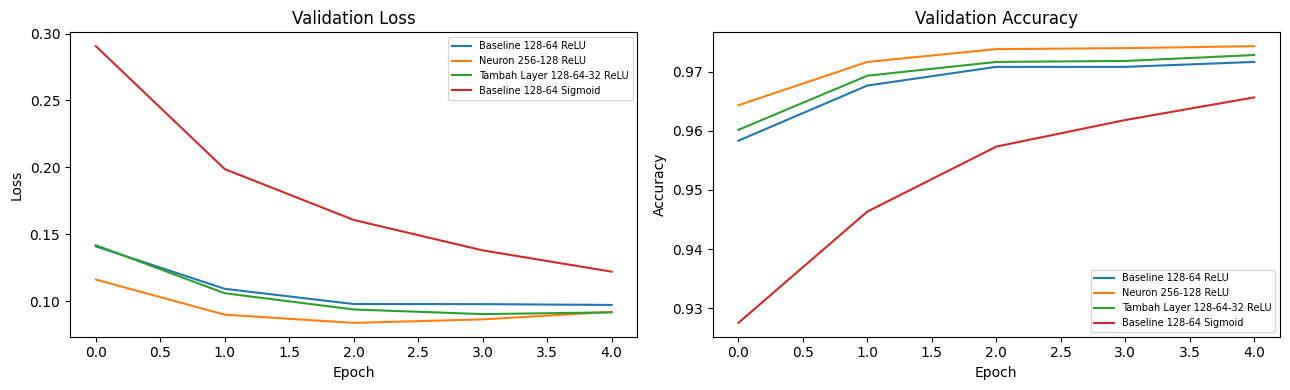

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for r in results:
    axes[0].plot(r['history']['val_loss'], label=r['name'])
    axes[1].plot(r['history']['val_accuracy'], label=r['name'])

axes[0].set_title('Validation Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend(fontsize=7)

axes[1].set_title('Validation Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend(fontsize=7)

plt.tight_layout()
plt.show()

## 8. Contoh Hasil Prediksi

Model dengan akurasi data uji terbaik digunakan untuk menampilkan contoh prediksi. Label yang salah diprediksi ditandai dengan warna merah.

Model terbaik: Neuron 256-128 ReLU (akurasi 0.9728)


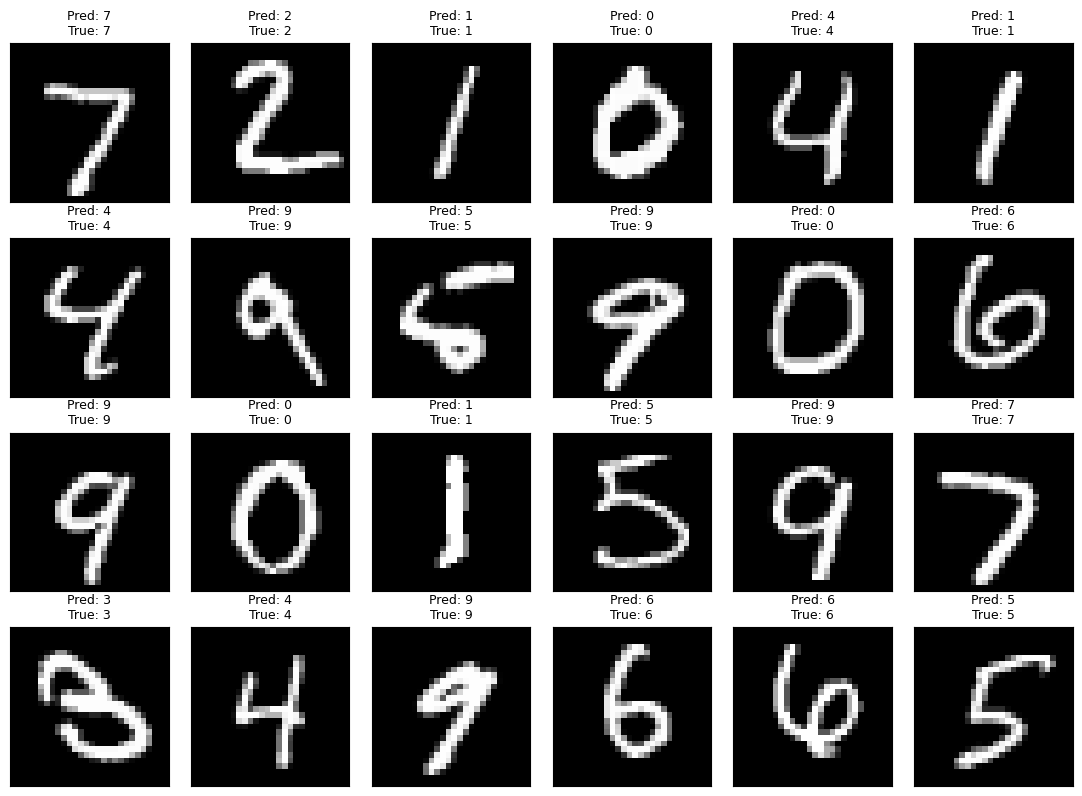

In [9]:
best = max(results, key=lambda r: r['test_accuracy'])
print('Model terbaik:', best['name'], f"(akurasi {best['test_accuracy']:.4f})")

predictions = best['model'].predict(X_test[:24], verbose=0)
pred_labels = np.argmax(predictions, axis=1)
true_labels = y_test[:24]

fig, axes = plt.subplots(4, 6, figsize=(11, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_test[i], cmap='gray')
    ax.set_xticks([])
    ax.set_yticks([])
    warna = 'black' if pred_labels[i] == true_labels[i] else 'red'
    ax.set_title(f'Pred: {pred_labels[i]}\nTrue: {true_labels[i]}',
                 color=warna, fontsize=9)

plt.tight_layout()
plt.show()

## 9. Analisis Hasil

Seluruh angka pada bagian ini diambil dari output aktual notebook.

| Konfigurasi | Hidden Layers | Aktivasi | Test Accuracy | Test Loss | Waktu (s) | Parameter |
|---|---|---|---:|---:|---:|---:|
| Baseline 128-64 | 128-64 | ReLU | 0.9690 | 0.1013 | 15.06 | 109.386 |
| Neuron 256-128 | 256-128 | ReLU | **0.9728** | **0.0907** | 22.22 | 235.146 |
| Tambah Layer 128-64-32 | 128-64-32 | ReLU | 0.9707 | 0.0965 | 17.95 | 111.146 |
| Baseline 128-64 | 128-64 | Sigmoid | 0.9556 | 0.1454 | 15.22 | 109.386 |

### Pembahasan

1. **Model terbaik adalah 256-128 ReLU.** Akurasi data uji **0.9728** dengan loss **0.0907**. Dibandingkan baseline 128-64 ReLU, akurasi naik **0.38 poin persentase** dan loss turun sekitar **10.46%**.

2. **Kenaikan akurasi dibayar dengan biaya komputasi.** Jumlah parameter naik dari **109.386** menjadi **235.146** (sekitar **2.15x**), dan waktu training naik dari **15.06 s** menjadi **22.22 s** (sekitar **1.48x**). Pada data uji 10.000 gambar, kenaikan 0.38 poin setara sekitar **38 gambar** yang berpindah dari salah menjadi benar.

3. **Menambah satu hidden layer tidak memberi peningkatan besar.** Konfigurasi 128-64-32 memperoleh akurasi **0.9707**, hanya **0.17 poin** di atas baseline, dengan tambahan parameter yang kecil (**1.760**) dan waktu **17.95 s**. Arsitektur ini tidak seefisien 256-128 dalam hal akurasi per parameter.

4. **Sigmoid paling rendah.** Akurasinya **0.9556**, sekitar **1.34 poin** di bawah baseline ReLU, dan loss **0.1454**, sekitar **43.53%** lebih tinggi. Dengan hanya 5 epoch, Sigmoid mengalami konvergensi lebih lambat karena gradiennya mengecil pada nilai ekstrem.

5. **Semua model masih mungkin underfit.** Training hanya 5 epoch tanpa early stopping, sehingga akurasi kemungkinan masih dapat naik. Peringkat konfigurasi bisa berubah jika epoch ditambah atau learning rate disesuaikan.

6. **Model terbaik dipakai untuk contoh prediksi.** Notebook memilih **256-128 ReLU** dan menampilkan 24 gambar uji beserta label prediksi dan label sebenarnya. Jumlah kesalahan pada 24 gambar tersebut tidak dicetak sebagai angka, sehingga tidak dihitung di sini.

### Kesimpulan

1. **256-128 ReLU** memberikan akurasi tertinggi (**97.28%**) dan loss terendah (**0.0907**) pada 5 epoch.
2. **Baseline 128-64 ReLU** sudah kuat (**96.90%**) dengan parameter dan waktu paling rendah di antara model ReLU.
3. **Menambah layer** tidak sepadan dengan kenaikan performanya pada konfigurasi ini.
4. **ReLU mengungguli Sigmoid** secara konsisten pada arsitektur yang sama, baik dari akurasi maupun loss.